In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [21]:
df=pd.read_csv('bank.csv')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [22]:
df.shape

(8912, 17)

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [24]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df.isna().sum()

age            0
job            7
marital      169
education     27
default        4
balance       13
housing       13
loan          30
contact       31
day           19
month         28
duration       7
campaign       8
pdays        145
previous       3
poutcome       0
deposit        9
dtype: int64

In [27]:
df.dropna(subset=['deposit'], inplace=True)
df.reset_index(drop=True, inplace=True)

In [28]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
for col in df.select_dtypes(include='object'):
    df[[col]] = imputer.fit_transform(df[[col]])


In [29]:
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
for col in ['day']:
    df[[col]] = imputer.fit_transform(df[[col]])

In [30]:
imputer = SimpleImputer(missing_values=np.nan, strategy='median')
for col in ['balance',  'pdays', 'previous', 'duration', 'campaign']:
    df[[col]] = imputer.fit_transform(df[[col]])

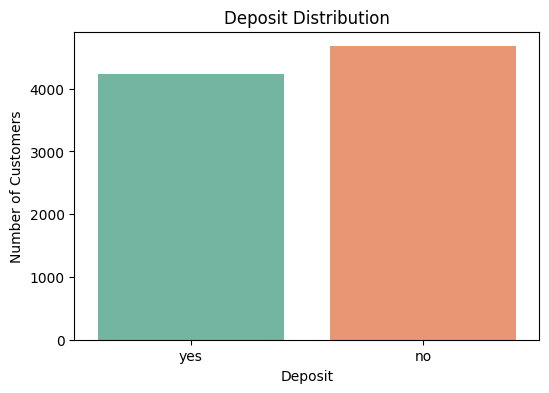

In [31]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='deposit', hue='deposit', palette='Set2', legend=False)

plt.title('Deposit Distribution')
plt.xlabel('Deposit')
plt.ylabel('Number of Customers')
plt.show()

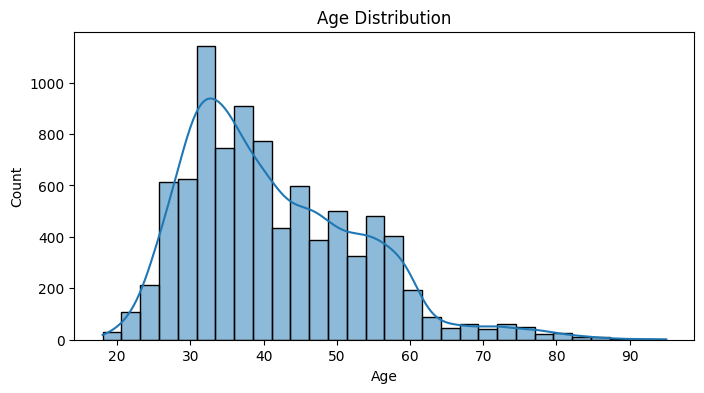

In [32]:
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

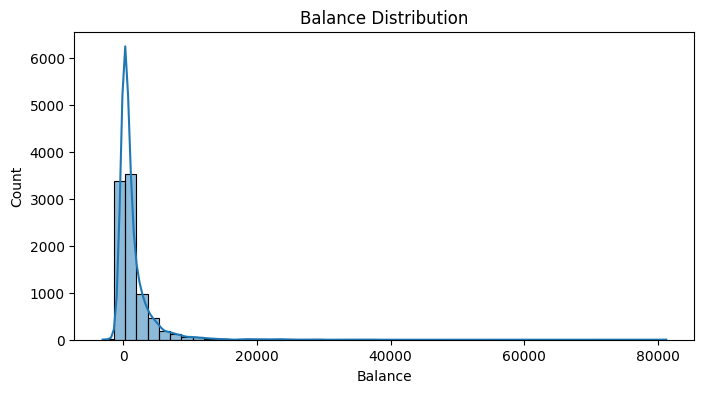

In [33]:
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x='balance', bins=50, kde=True)

plt.title('Balance Distribution')
plt.xlabel('Balance')
plt.ylabel('Count')
plt.show()

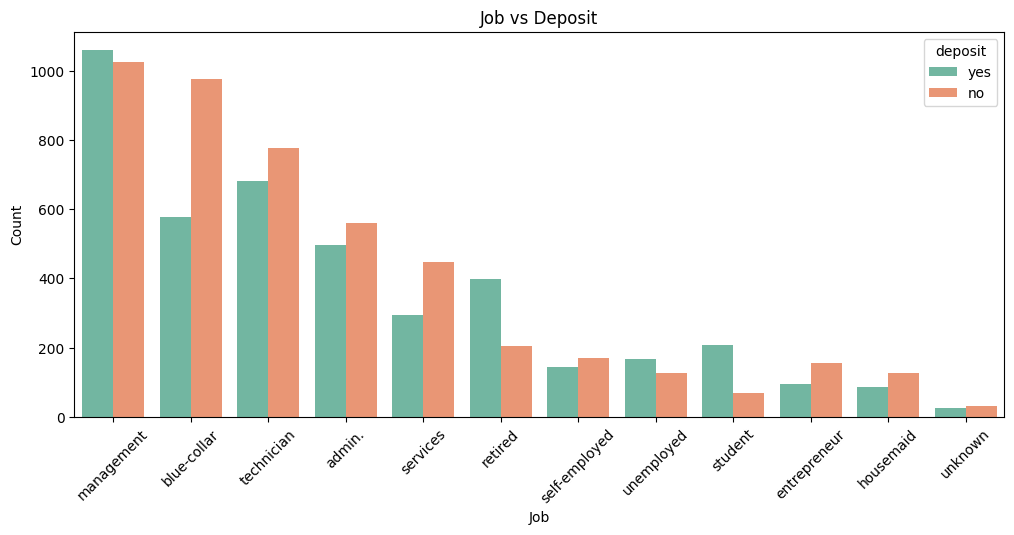

In [34]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x='job',
    hue='deposit',
    order=df['job'].value_counts().index,
    palette='Set2'
)

plt.title('Job vs Deposit')
plt.xlabel('Job')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

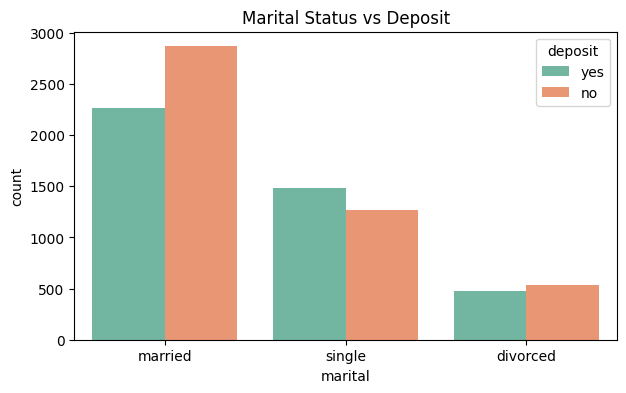

In [35]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='marital', hue='deposit', palette='Set2')

plt.title('Marital Status vs Deposit')
plt.show()

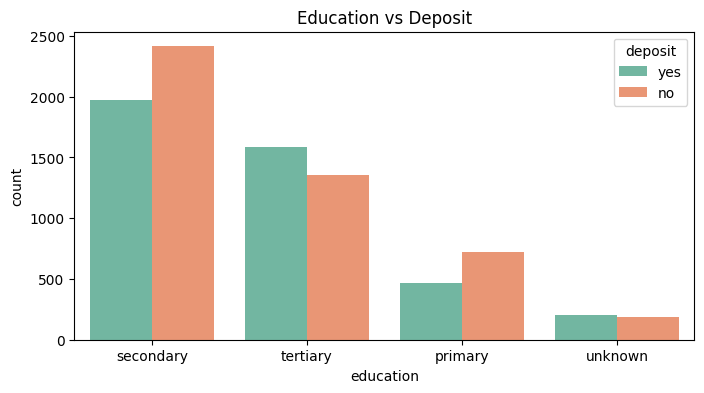

In [36]:
plt.figure(figsize=(8, 4))

sns.countplot(data=df, x='education', hue='deposit', palette='Set2')

plt.title('Education vs Deposit')
plt.show()

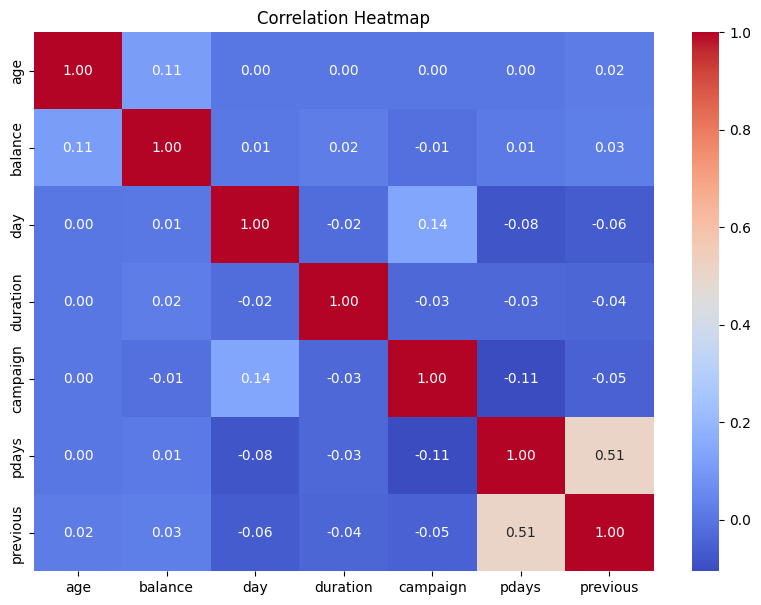

In [37]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [38]:
df.select_dtypes(include=['object']).nunique()

job          12
marital       3
education     4
default       2
housing       2
loan          2
contact       3
month        12
poutcome      4
deposit       2
dtype: int64

In [39]:
from sklearn.preprocessing import OneHotEncoder
onehot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

temp = onehot.fit_transform(df[['marital','education','contact','poutcome']])
df = pd.concat([df,temp],axis=1)
df.drop(['marital','education','contact','poutcome'],axis=1,inplace=True)

In [40]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in [ 'default', 'housing', 'loan', 'deposit']:
    df[col] = le.fit_transform(df[col]) 



In [41]:
X=df.drop('deposit', axis=1)
y=df['deposit']

In [42]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (7122, 22)  y_train =  (7122,)
X_test  =  (1781, 22)  y_test  =  (1781,)


In [43]:
import category_encoders as ce
target_enc = ce.TargetEncoder(
    cols=['job','month'],
    smoothing=5
)

X_train[['job_new','month_new']] = target_enc.fit_transform(
    X_train[['job','month']],
    y_train
)
X_test[['job_new','month_new']] = target_enc.transform(
    X_test[['job','month']]
)


In [44]:
X_train.drop(columns=['job','month'], inplace=True)
X_test.drop(columns=['job','month'], inplace=True)

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [46]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[781 154]
 [172 674]]


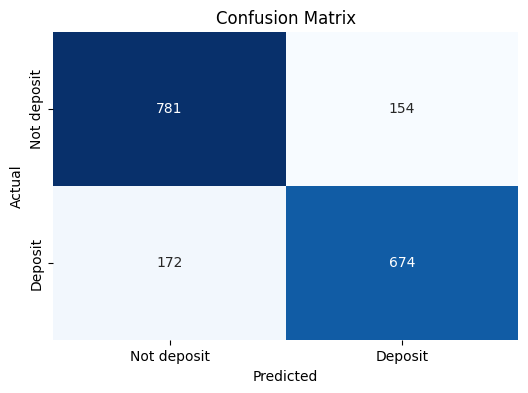


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.82      0.84      0.83       935
      Stroke       0.81      0.80      0.81       846

    accuracy                           0.82      1781
   macro avg       0.82      0.82      0.82      1781
weighted avg       0.82      0.82      0.82      1781

ROC-AUC: 0.8897017736817486


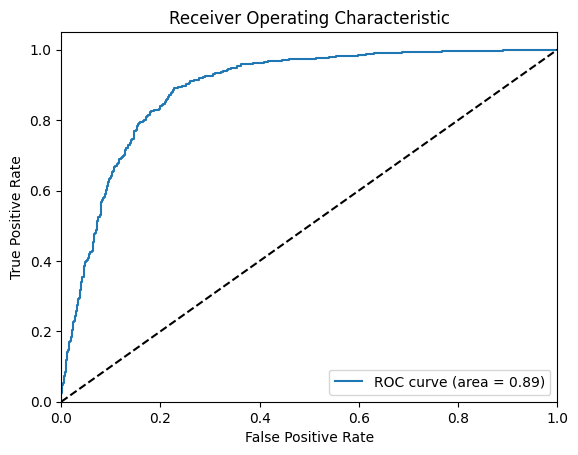

PR AUC: 0.8489402709395283


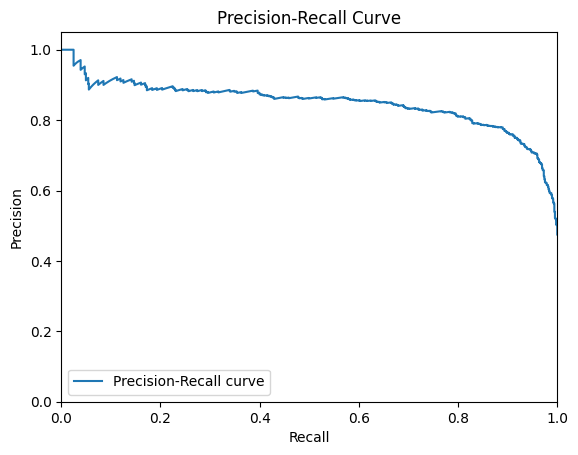

  8%|▊         | 1/13 [00:01<00:12,  1.01s/it]


Confusion Matrix:
 [[772 163]
 [214 632]]


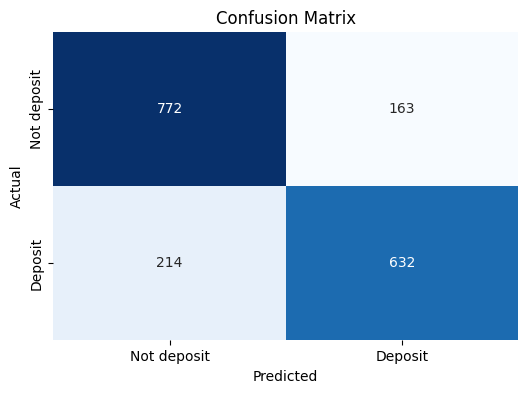


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.78      0.83      0.80       935
      Stroke       0.79      0.75      0.77       846

    accuracy                           0.79      1781
   macro avg       0.79      0.79      0.79      1781
weighted avg       0.79      0.79      0.79      1781

ROC-AUC: 0.8474684264421437


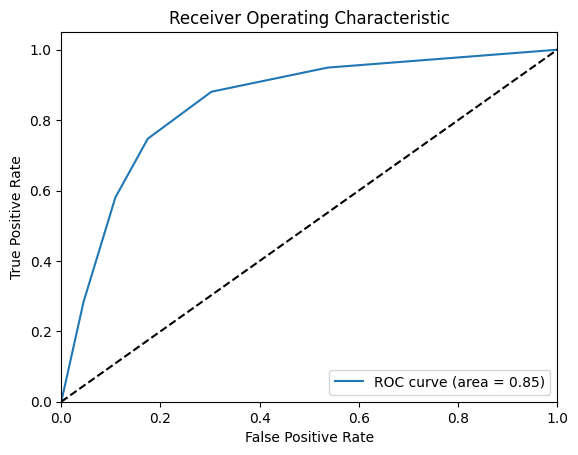

PR AUC: 0.7827171488526571


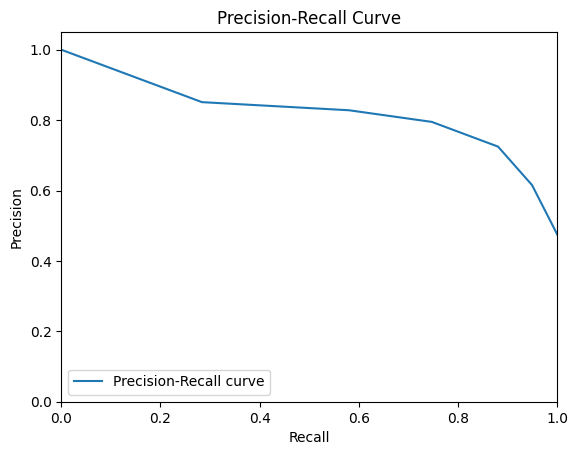

 15%|█▌        | 2/13 [00:04<00:24,  2.21s/it]


Confusion Matrix:
 [[765 170]
 [122 724]]


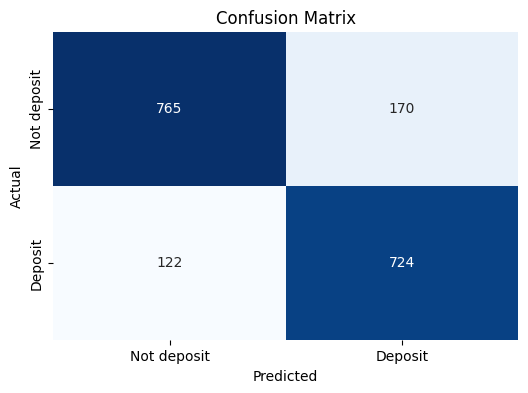


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.86      0.82      0.84       935
      Stroke       0.81      0.86      0.83       846

    accuracy                           0.84      1781
   macro avg       0.84      0.84      0.84      1781
weighted avg       0.84      0.84      0.84      1781

ROC-AUC: 0.8941859142109454


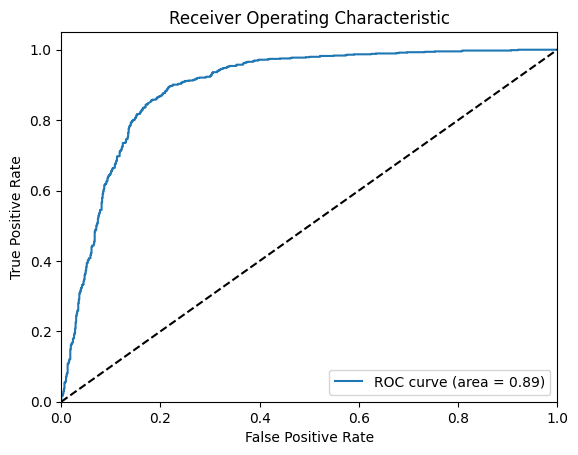

PR AUC: 0.8430573684240404


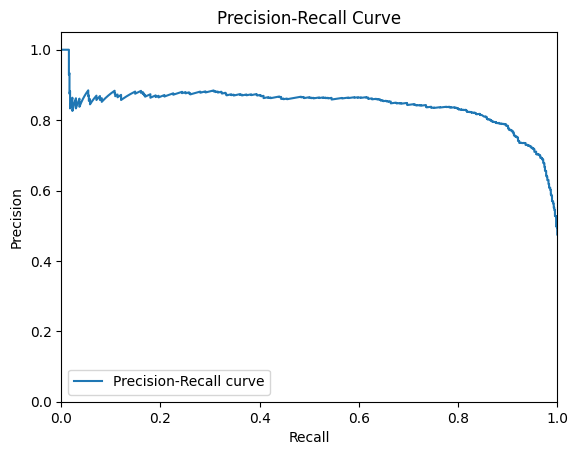

 23%|██▎       | 3/13 [00:31<02:17, 13.73s/it]


Confusion Matrix:
 [[740 195]
 [182 664]]


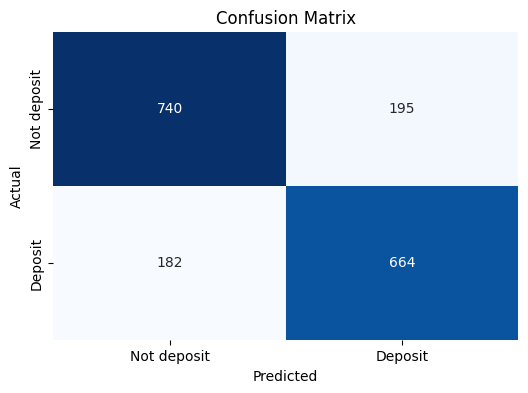


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.80      0.79      0.80       935
      Stroke       0.77      0.78      0.78       846

    accuracy                           0.79      1781
   macro avg       0.79      0.79      0.79      1781
weighted avg       0.79      0.79      0.79      1781

ROC-AUC: 0.7881569133133589


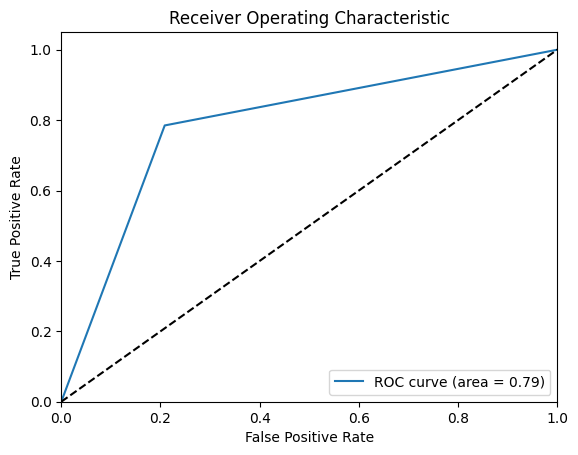

PR AUC: 0.7088878768340054


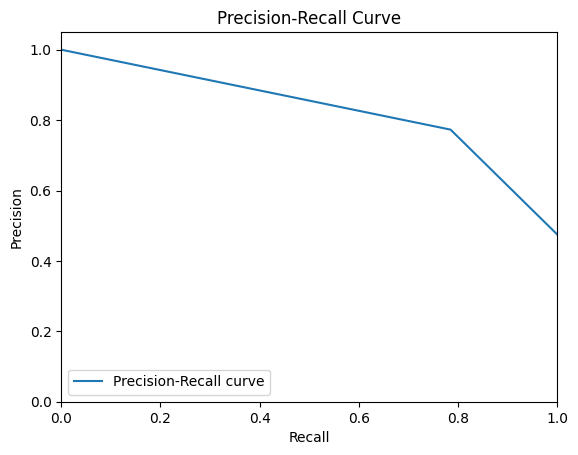

 31%|███       | 4/13 [00:32<01:18,  8.73s/it]


Confusion Matrix:
 [[752 183]
 [275 571]]


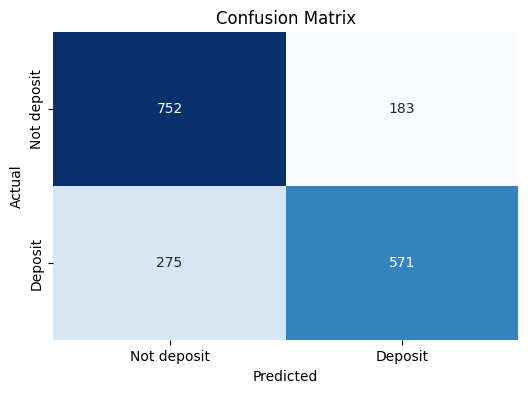


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.73      0.80      0.77       935
      Stroke       0.76      0.67      0.71       846

    accuracy                           0.74      1781
   macro avg       0.74      0.74      0.74      1781
weighted avg       0.74      0.74      0.74      1781

ROC-AUC: 0.8189068406214839


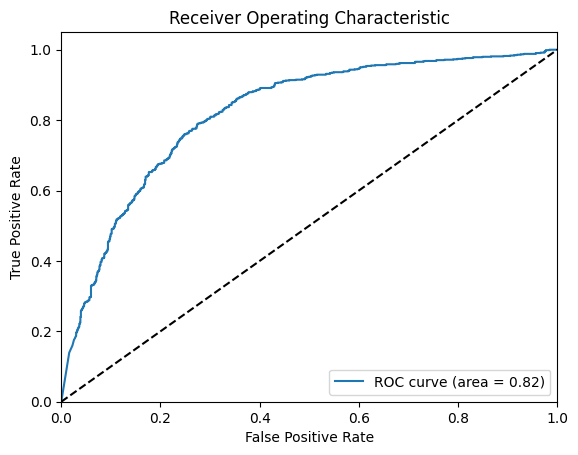

PR AUC: 0.7778869055151293


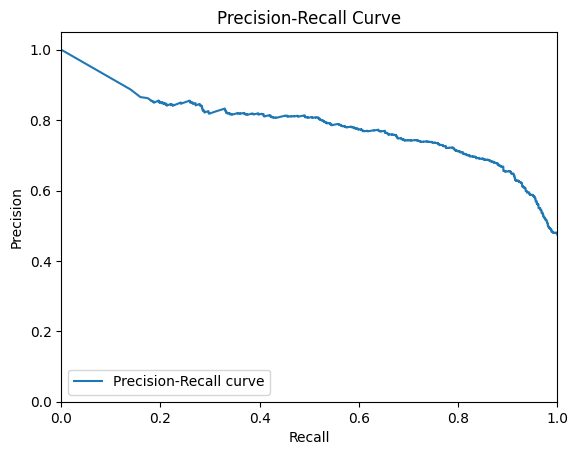

 38%|███▊      | 5/13 [00:33<00:46,  5.84s/it]


Confusion Matrix:
 [[768 167]
 [ 96 750]]


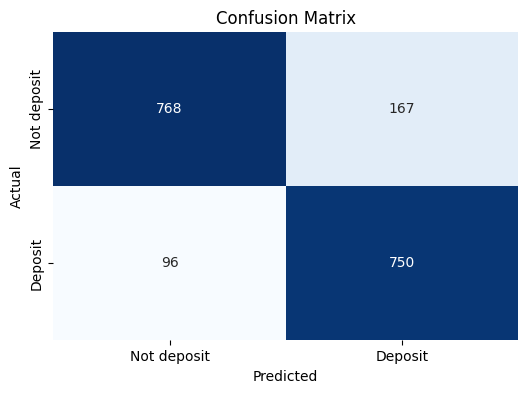


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.82      0.85       935
      Stroke       0.82      0.89      0.85       846

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.86      0.85      0.85      1781

ROC-AUC: 0.9073905513204638


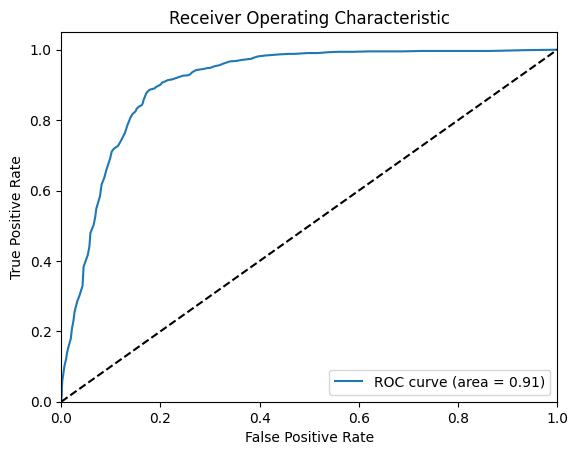

PR AUC: 0.8647371716479519


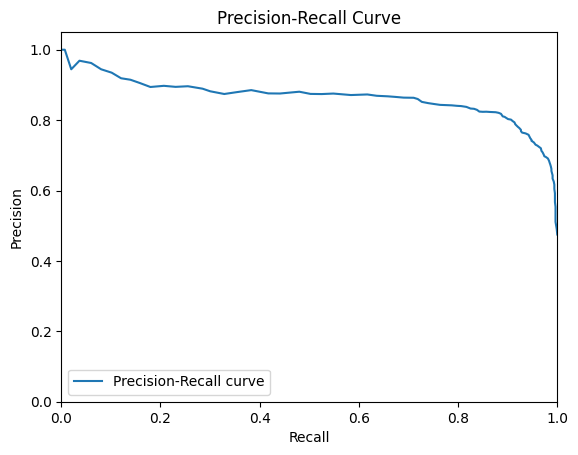

 46%|████▌     | 6/13 [00:36<00:33,  4.86s/it]


Confusion Matrix:
 [[768 167]
 [141 705]]


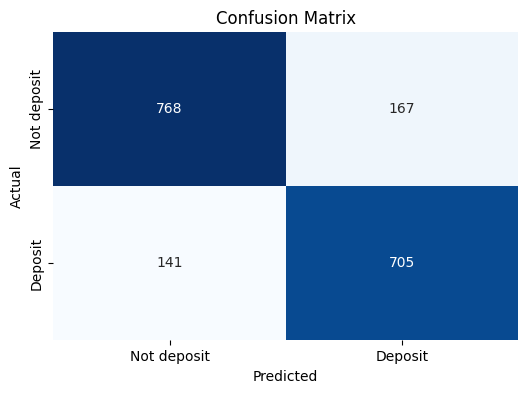


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.84      0.82      0.83       935
      Stroke       0.81      0.83      0.82       846

    accuracy                           0.83      1781
   macro avg       0.83      0.83      0.83      1781
weighted avg       0.83      0.83      0.83      1781

ROC-AUC: 0.8978679157027092


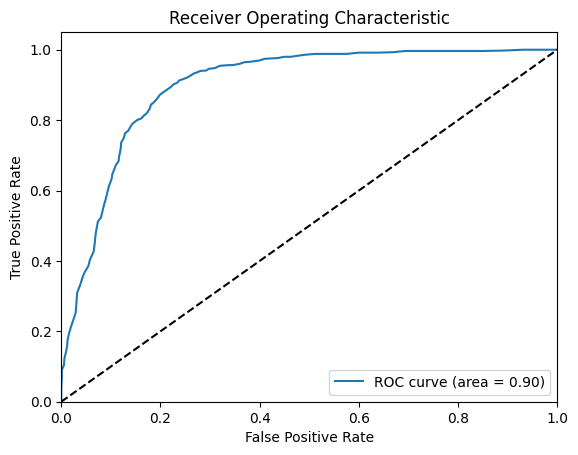

PR AUC: 0.8599406666716403


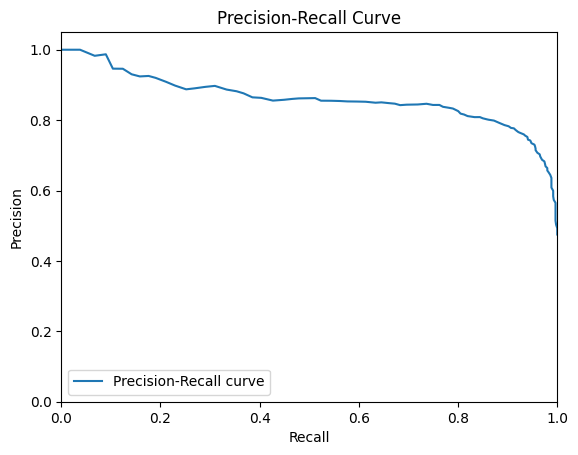

 54%|█████▍    | 7/13 [00:38<00:24,  4.01s/it]


Confusion Matrix:
 [[780 155]
 [178 668]]


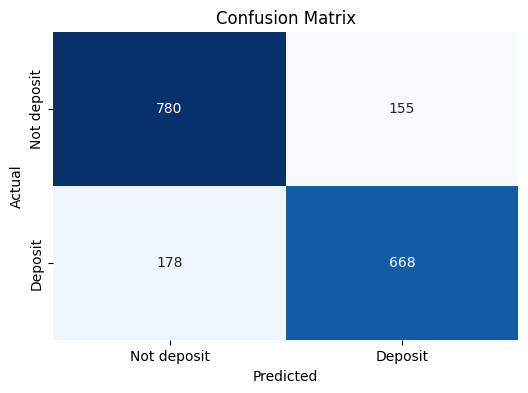


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.81      0.83      0.82       935
      Stroke       0.81      0.79      0.80       846

    accuracy                           0.81      1781
   macro avg       0.81      0.81      0.81      1781
weighted avg       0.81      0.81      0.81      1781

ROC-AUC: 0.8872422598955765


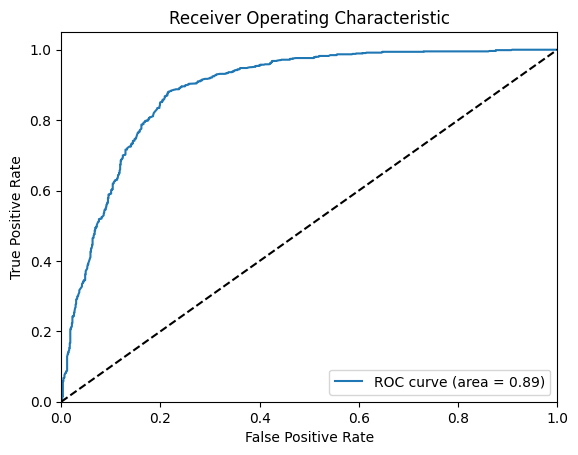

PR AUC: 0.8424174571658921


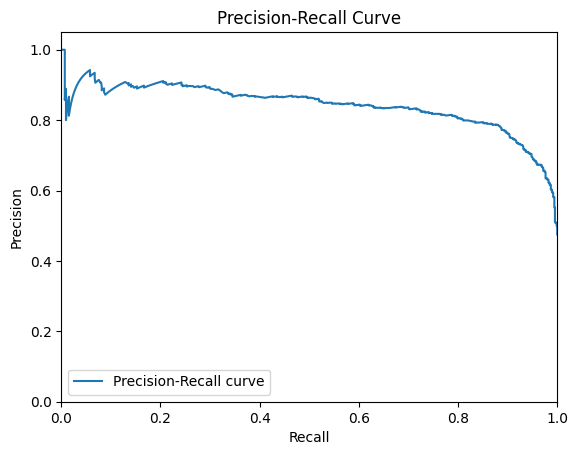

 62%|██████▏   | 8/13 [00:40<00:16,  3.29s/it]


Confusion Matrix:
 [[765 170]
 [106 740]]


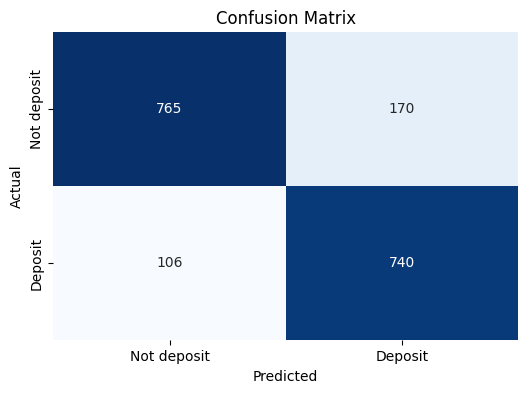


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.82      0.85       935
      Stroke       0.81      0.87      0.84       846

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9082350412763429


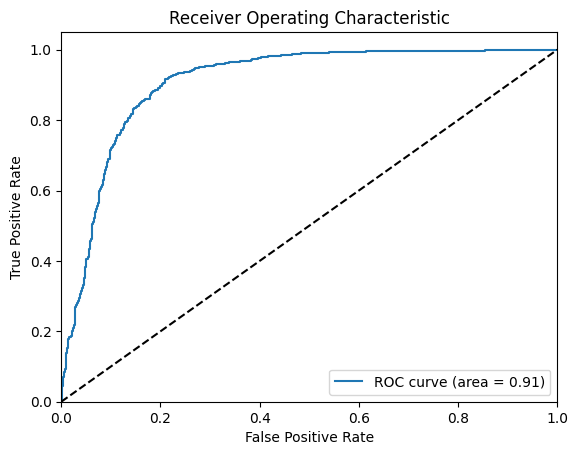

PR AUC: 0.8626164887041794


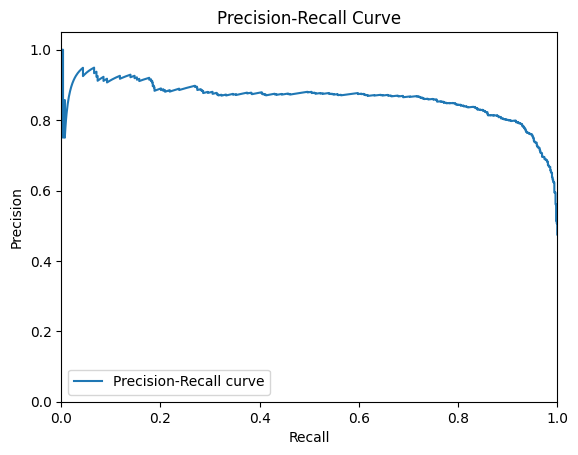

 69%|██████▉   | 9/13 [00:43<00:13,  3.25s/it]


Confusion Matrix:
 [[768 167]
 [ 97 749]]


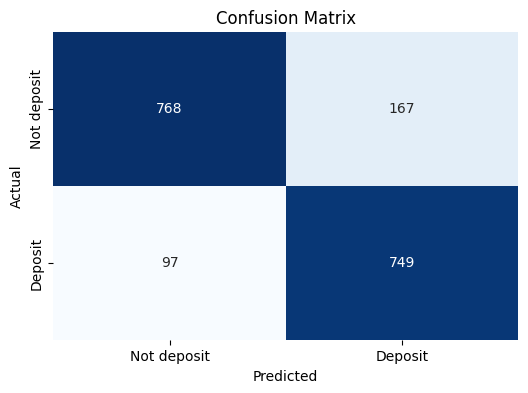


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.82      0.85       935
      Stroke       0.82      0.89      0.85       846

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9184371878990151


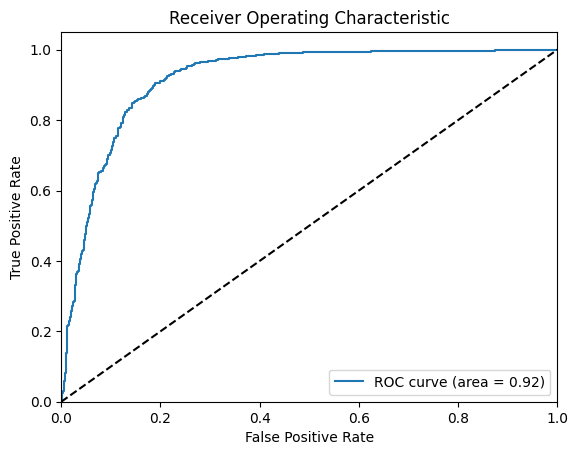

PR AUC: 0.875579250305801


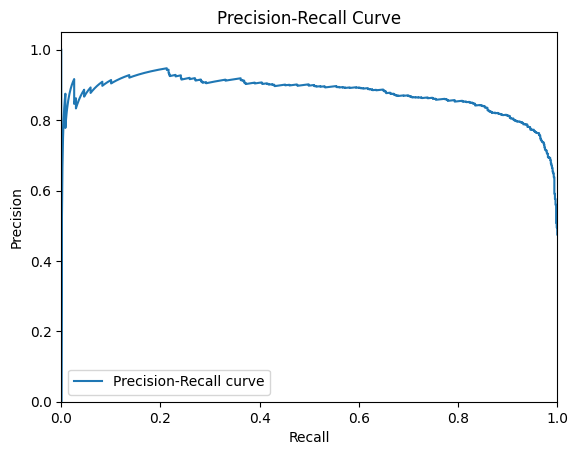

 77%|███████▋  | 10/13 [00:45<00:08,  2.86s/it]c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [00:10:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[764 171]
 [107 739]]


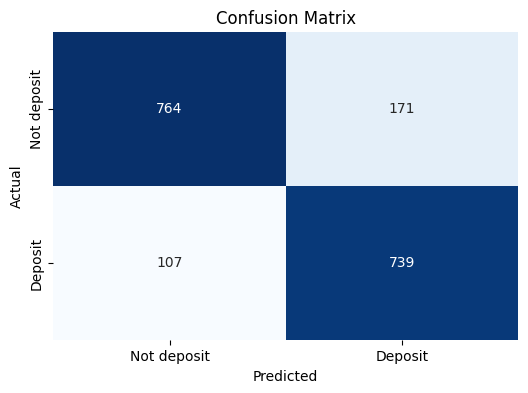


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.82      0.85       935
      Stroke       0.81      0.87      0.84       846

    accuracy                           0.84      1781
   macro avg       0.84      0.85      0.84      1781
weighted avg       0.85      0.84      0.84      1781

ROC-AUC: 0.91263827258821


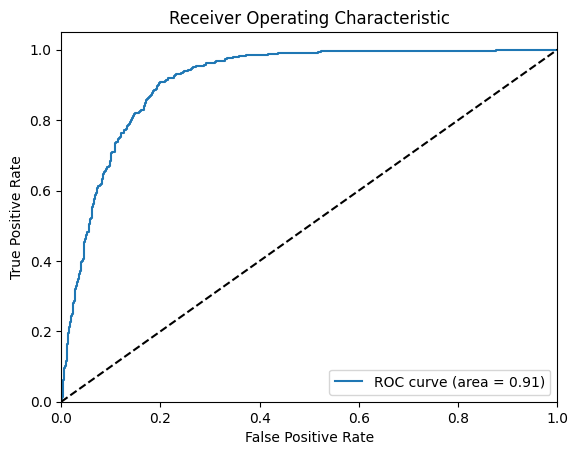

PR AUC: 0.8701351415516592


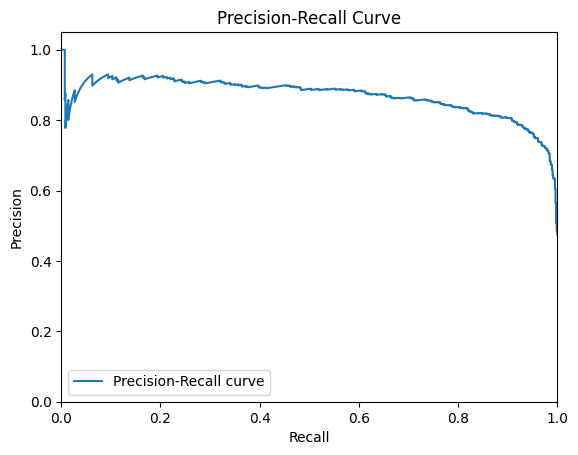

 85%|████████▍ | 11/13 [00:46<00:04,  2.34s/it]


Confusion Matrix:
 [[778 157]
 [105 741]]


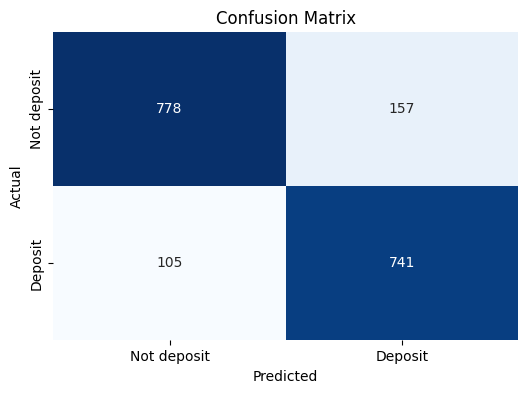


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.83      0.86       935
      Stroke       0.83      0.88      0.85       846

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9178746159972693


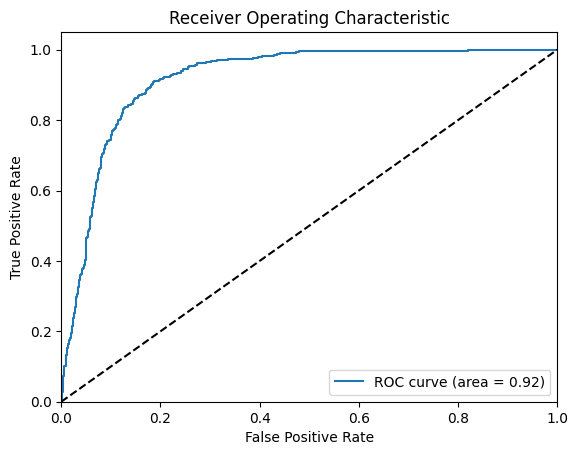

PR AUC: 0.8738907104103583


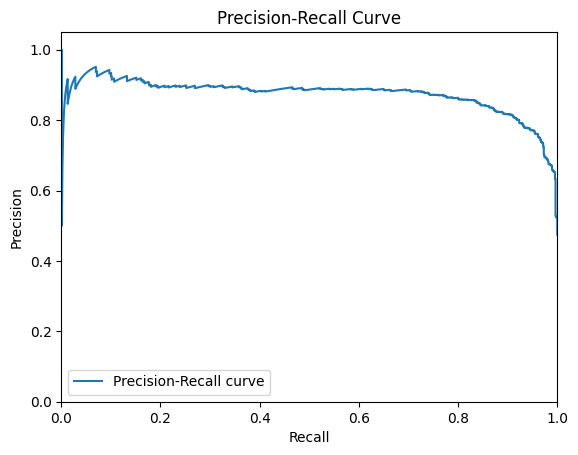

 92%|█████████▏| 12/13 [00:58<00:05,  5.39s/it]

[LightGBM] [Info] Number of positive: 3384, number of negative: 3738
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003039 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 988
[LightGBM] [Info] Number of data points in the train set: 7122, number of used features: 22
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.475147 -> initscore=-0.099492
[LightGBM] [Info] Start training from score -0.099492

Confusion Matrix:
 [[760 175]
 [ 92 754]]


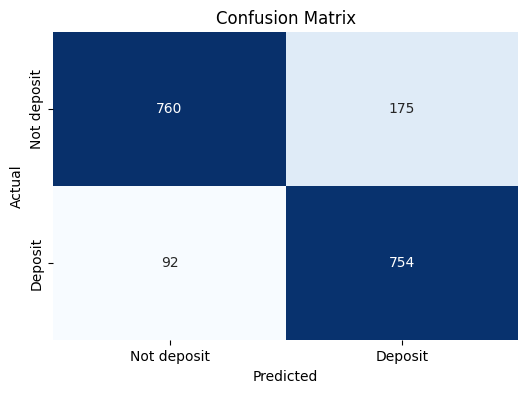


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.89      0.81      0.85       935
      Stroke       0.81      0.89      0.85       846

    accuracy                           0.85      1781
   macro avg       0.85      0.85      0.85      1781
weighted avg       0.85      0.85      0.85      1781

ROC-AUC: 0.9161616161616162


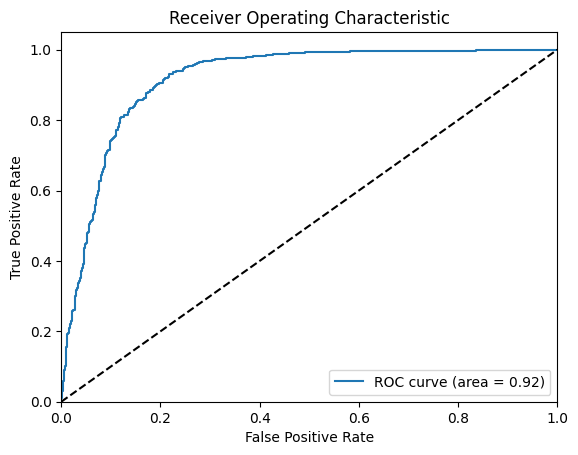

PR AUC: 0.8753203450866426


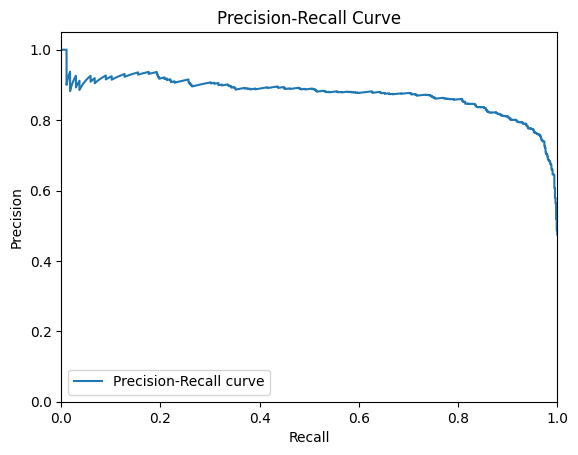

100%|██████████| 13/13 [01:00<00:00,  4.68s/it]


In [47]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)
    
    

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['Not deposit','Deposit']
                ,yticklabels=['Not deposit','Deposit'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--') 
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }
    

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [00:10:53] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[785 150]
 [132 714]]


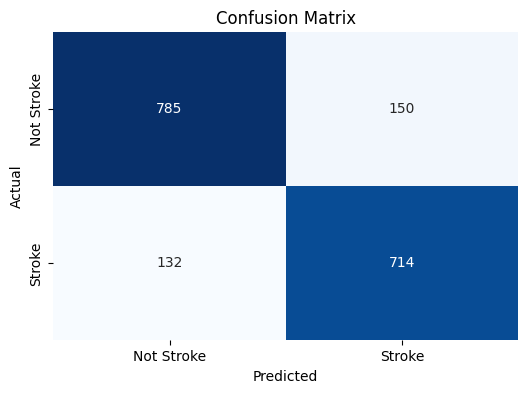


Classification Report:

              precision    recall  f1-score   support

 Not deposit       0.86      0.84      0.85       935
     Deposit       0.83      0.84      0.84       846

    accuracy                           0.84      1781
   macro avg       0.84      0.84      0.84      1781
weighted avg       0.84      0.84      0.84      1781

ROC-AUC: 0.9050340703657351


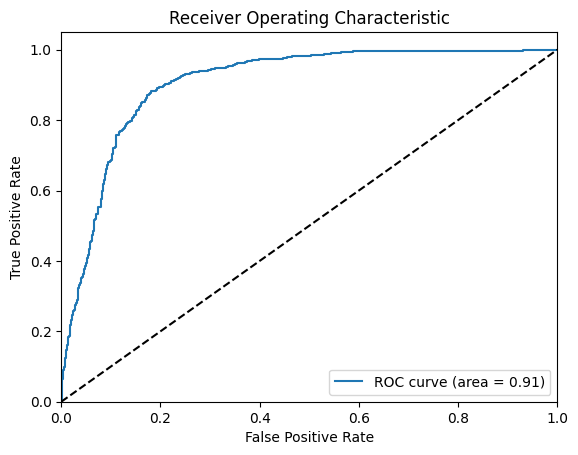

PR AUC: 0.866266175334868


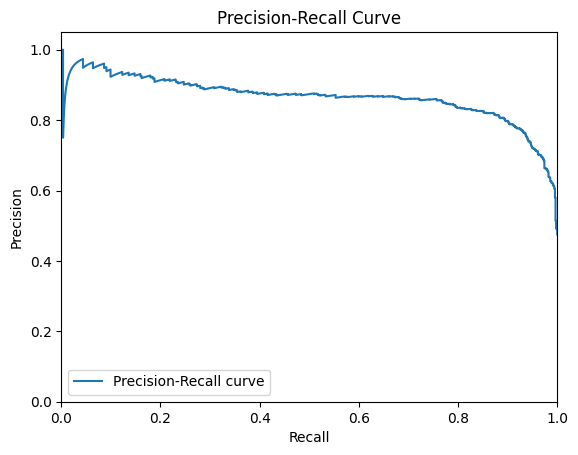

In [48]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['Not deposit','Deposit'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

c:\Users\Administrator\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:200: UserWarning: [00:11:15] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "max_iter" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[749 186]
 [ 98 748]]


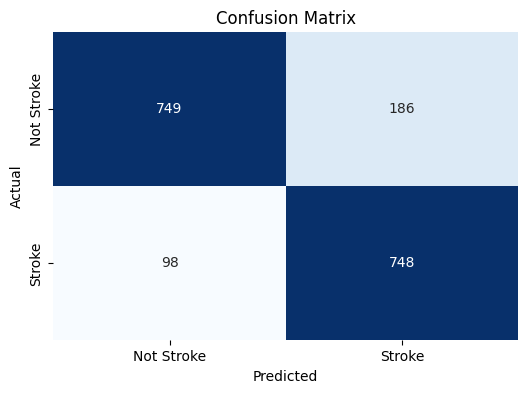


Classification Report:

              precision    recall  f1-score   support

  Not Stroke       0.88      0.80      0.84       935
      Stroke       0.80      0.88      0.84       846

    accuracy                           0.84      1781
   macro avg       0.84      0.84      0.84      1781
weighted avg       0.84      0.84      0.84      1781

ROC-AUC: 0.9063532698701661


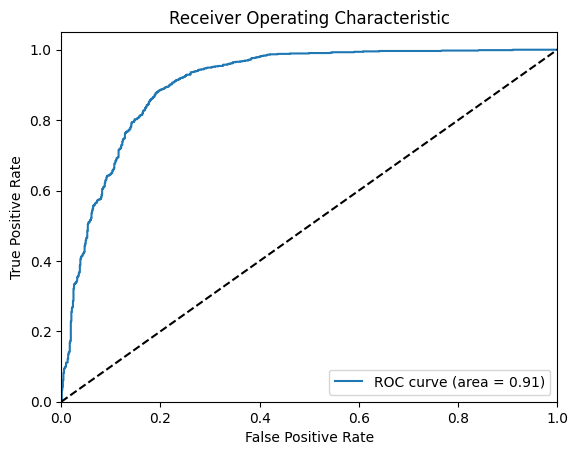

PR AUC: 0.865679399494822


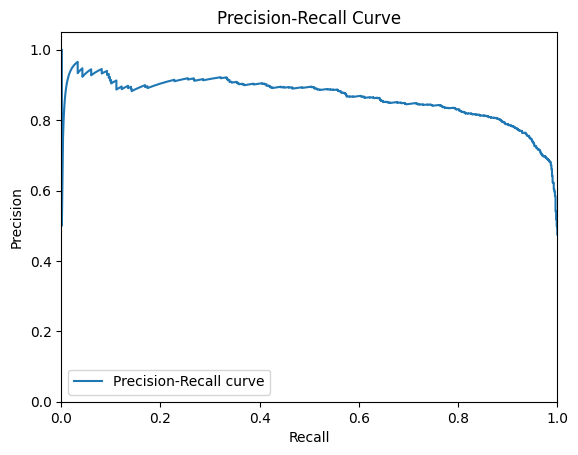

In [49]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),

        
    ],
    final_estimator=XGBClassifier(max_iter=2000),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['Not Stroke','Stroke']
            ,yticklabels=['Not Stroke','Stroke'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['Not Stroke','Stroke'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--') 
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [50]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Random Forest,1.000000,0.852330,1.000000,0.817884,1.000000,0.886525,1.000000,0.850822,1.000000,0.853958,0.907391,0.864737
Hist Gradient Boosting,0.921792,0.851769,0.890578,0.817686,0.952423,0.885343,0.920463,0.850170,0.923242,0.853367,0.918437,0.875579
CatBoost,0.916316,0.852892,0.893563,0.825167,0.935284,0.875887,0.913947,0.849771,0.917214,0.853986,0.917875,0.873891
LightGBM,0.919685,0.850084,0.890773,0.811625,0.947104,0.891253,0.918075,0.849577,0.920984,0.852044,0.916162,0.875320
Gradient Boosting,0.860292,0.845031,0.838481,0.813187,0.874409,0.874704,0.856068,0.842825,0.860961,0.846443,0.908235,0.862616
XGBoost,0.975288,0.843908,0.968184,0.812088,0.980201,0.873522,0.974156,0.841686,0.975520,0.845317,0.912638,0.870135
Stacking Classifier,0.918141,0.840539,0.897982,0.800857,0.933806,0.884161,0.915544,0.840449,0.918883,0.842615,0.906353,0.865679
Voting Classifier,0.923336,0.841662,0.916618,0.826389,0.922577,0.843972,0.919588,0.835088,0.923300,0.841772,0.905034,0.866266
SVC,0.861977,0.836047,0.845269,0.809843,0.868499,0.855792,0.856726,0.832184,0.862286,0.836987,0.894186,0.843057
Extra Trees,1.000000,0.827063,1.000000,0.808486,1.000000,0.833333,1.000000,0.820722,1.000000,0.827362,0.897868,0.859941


<Axes: >

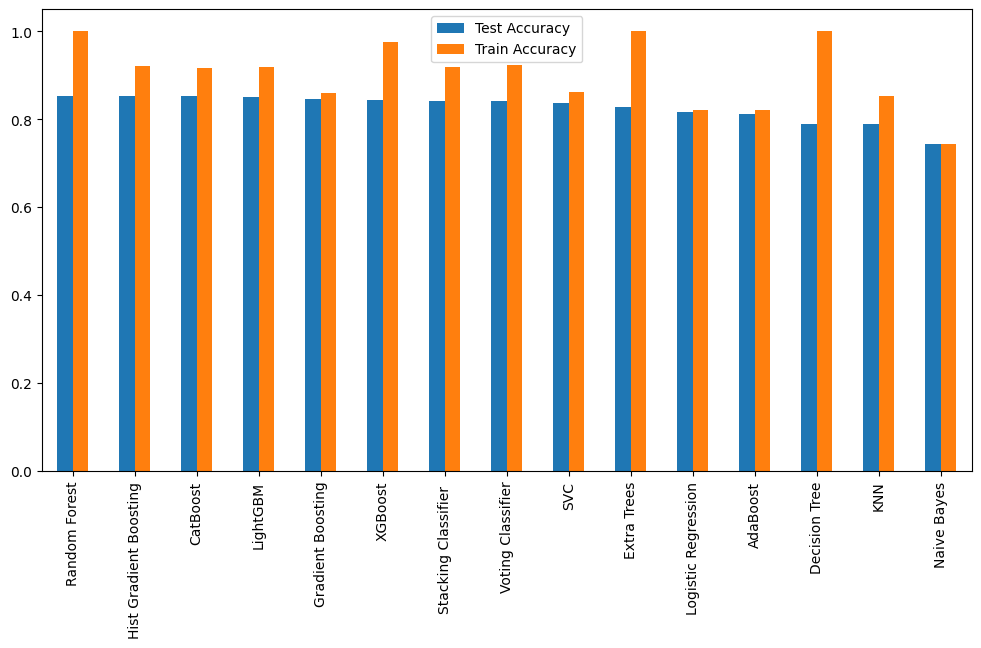

In [51]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

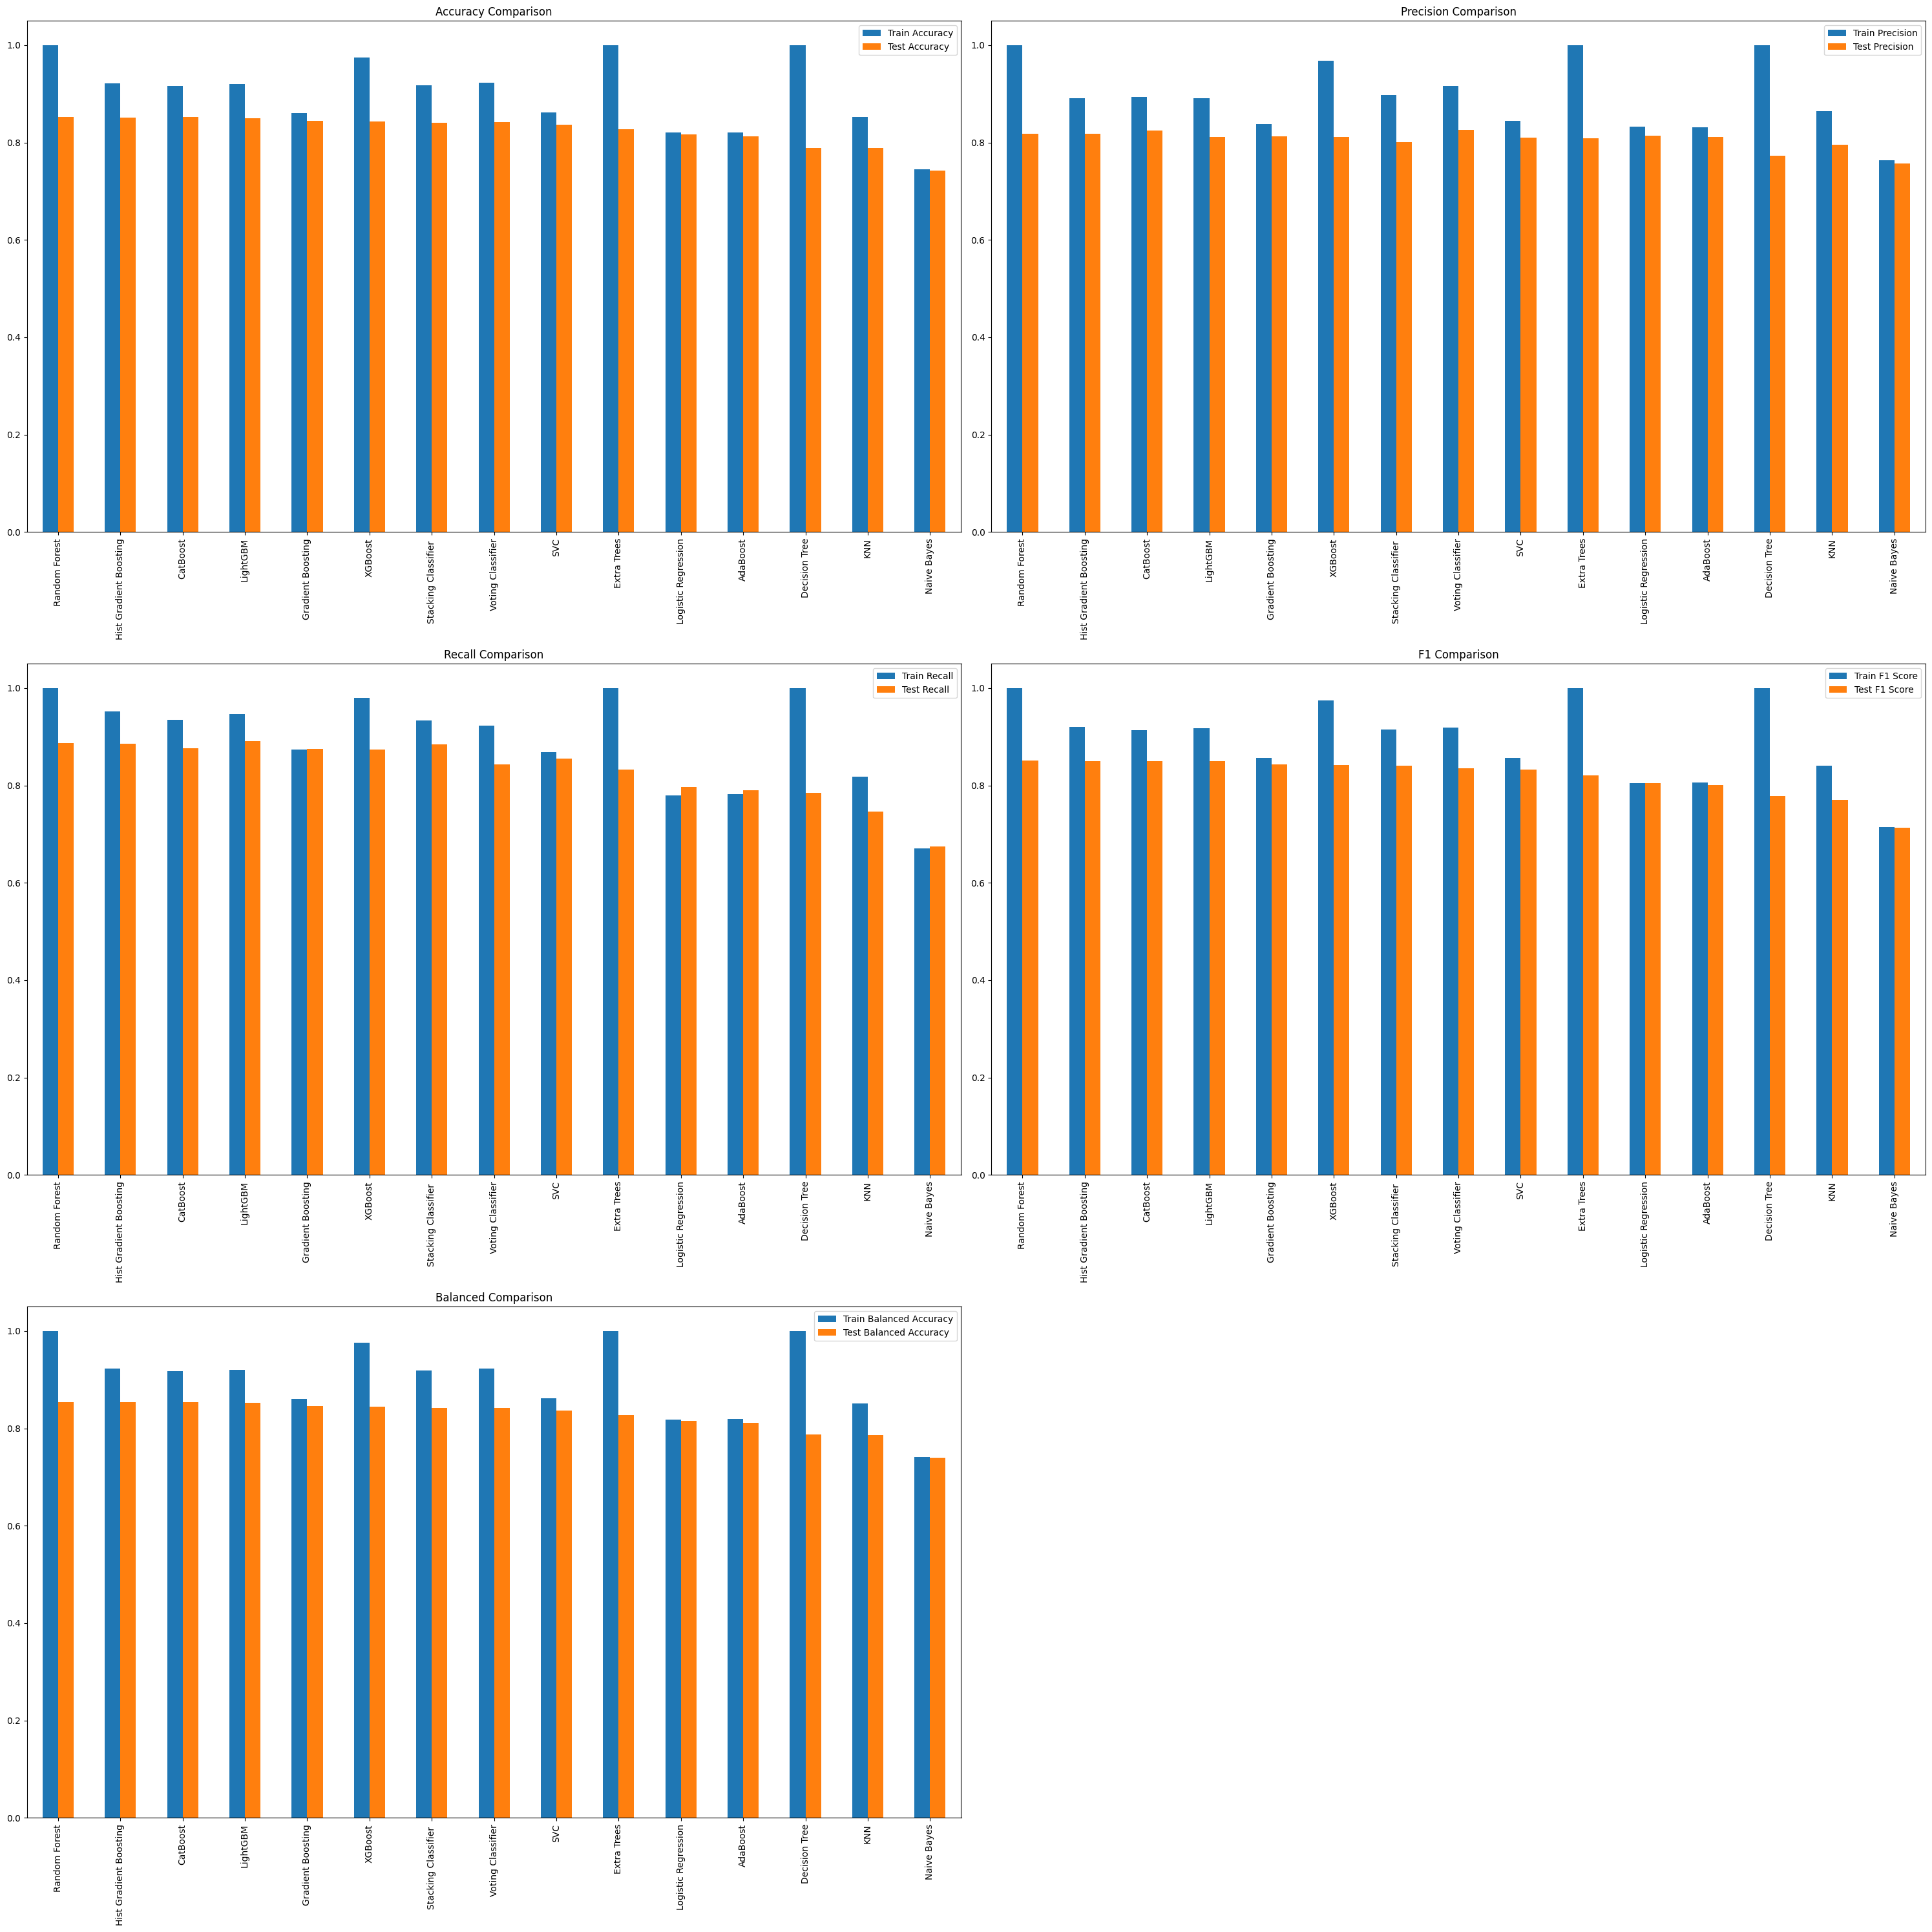

In [52]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)   
    results_df[col].plot.bar(ax=ax)   
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

